# 🧪 Đánh Giá (Test) & Trực Quan Hóa (Visualization) — Bộ Dữ Liệu Bank Marketing
Notebook này chịu trách nhiệm **nạp checkpoint, đánh giá kiểm thử độc lập (Test Accuracy)** và **trực quan hóa đối sánh toàn diện** cho **15 biến thể PSO** trên bộ dữ liệu **Bank Marketing** (bài toán phân loại nhị phân 16 đặc trưng).

Cấu trúc notebook được thiết kế chuẩn theo quy chuẩn học thuật của kỹ năng **Results Back-fill** (phục vụ trực tiếp việc viết mục **Results** cho bài báo khoa học LaTeX):
- **Phần 1: Thiết lập & Tiền xử lý dữ liệu kiểm thử** (Đồng bộ tuyệt đối với tập Train).
- **Phần 2: Đánh giá chi tiết 15 biến thể PSO** chia theo 4 nhóm thuật toán:
  - *Nhóm I: Cơ sở & Cải tiến vận tốc cổ điển (Biến thể 1 - 4)*
  - *Nhóm II: Cải tiến quỹ đạo & Động học vận tốc mới (Biến thể 5 - 8)*
  - *Nhóm III: Biến thể lượng tử nền tảng (Biến thể 9 - 11)*
  - *Nhóm IV: Biến thể lượng tử thích ứng nâng cao (Biến thể 12 - 15)*
- **Phần 3: Trực quan hóa tổng hợp & Xuất bảng LaTeX chuẩn Publication**:
  - *Lưới 3x5 không gian tìm kiếm 15 biến thể (tỉ lệ chuẩn vuông 1:1).*
  - *Biểu đồ hội tụ đồng quy 15 thuật toán.*
  - *Biểu đồ cột phân bố kép CV Score vs Test Accuracy.*
  - *Đối sánh đa tập dữ liệu (Bank Marketing vs Forest Covertype).*
  - *Trình tự động sinh mã nguồn LaTeX Table.*

## 📦 1. Cài đặt và Khai báo Thư viện

In [1]:
import os
import sys
import time
import math
import warnings
warnings.filterwarnings('ignore')

if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11

RANDOM_SEED = 42
print('✅ Đã nạp đầy đủ các thư viện kiểm thử và trực quan hóa!')
print(f'   NumPy   : {np.__version__}')
print(f'   Pandas  : {pd.__version__}')

✅ Đã nạp đầy đủ các thư viện kiểm thử và trực quan hóa!
   NumPy   : 1.26.4
   Pandas  : 2.2.2


## 📊 2. Tải và Tiền Xử Lý Dữ Liệu Kiểm Thử (Bank Marketing)
Quy trình phân chia Stratified Train (80%) và Test (20%) với `RANDOM_SEED = 42`, đồng bộ hoàn toàn với tiến trình huấn luyện.

In [2]:
data_path = '../data/raw/bank.csv'
if not os.path.exists(data_path):
    data_path = 'data/raw/bank.csv'

df = pd.read_csv(data_path)
df['deposit'] = df['deposit'].map({'yes': 1, 'no': 0})
cat_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

X = df_encoded.drop('deposit', axis=1).values
y = df_encoded['deposit'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

RESULT_CSV_PATH = '../results/test_results/test_accuracy.csv'
os.makedirs(os.path.dirname(RESULT_CSV_PATH), exist_ok=True)

print('=' * 60)
print('         DỮ LIỆU KIỂM THỬ BANK MARKETING ĐÃ SẴN SÀNG')
print('=' * 60)
print(f'  Tập huấn luyện (Train) : {X_train_sc.shape[0]:,} mẫu | {X_train_sc.shape[1]} đặc trưng')
print(f'  Tập kiểm thử   (Test)  : {X_test_sc.shape[0]:,} mẫu | 2 lớp phân loại')
print(f'  Tỉ lệ lớp Test         : Lớp 0 = {(y_test==0).sum():,}, Lớp 1 = {(y_test==1).sum():,}')
print('=' * 60)

         DỮ LIỆU KIỂM THỬ BANK MARKETING ĐÃ SẴN SÀNG
  Tập huấn luyện (Train) : 8,929 mẫu | 48 đặc trưng
  Tập kiểm thử   (Test)  : 2,233 mẫu | 2 lớp phân loại
  Tỉ lệ lớp Test         : Lớp 0 = 1,175, Lớp 1 = 1,058


## ⚙️ 3. Định Nghĩa Không Gian Tìm Kiếm & Hàm Đánh Giá Kiểm Thử
- **Không gian 3 chiều:**
  - $n_{neurons} \in [16, 256]$ (Số nơ-ron lớp ẩn)
  - $\log_{10}(lr) \in [-4.0, -1.0] \implies lr \in [10^{-4}, 10^{-1}]$
  - $\log_{10}(\alpha) \in [-5.0, -1.0] \implies \alpha \in [10^{-5}, 10^{-1}]$

In [3]:
LOW  = np.array([16,  -4.0, -5.0])
HIGH = np.array([256, -1.0, -1.0])

def decode_position(x):
    n_neurons = int(round(np.clip(x[0], LOW[0], HIGH[0])))
    lr        = float(10 ** np.clip(x[1], LOW[1], HIGH[1]))
    alpha     = float(10 ** np.clip(x[2], LOW[2], HIGH[2]))
    return n_neurons, lr, alpha

def evaluate_checkpoint(algo_name, ckpt_file, star_color='#e74c3c'):
    ckpt_path = f'../results/checkpoints/{ckpt_file}'
    data = joblib.load(ckpt_path)
    gbest = data['gbest_pos']
    cv_score = data['cv_score']
    n_b, lr_b, al_b = decode_position(gbest)
    
    mlp = MLPClassifier(
        hidden_layer_sizes=(n_b, n_b),
        activation='relu',
        learning_rate_init=lr_b,
        alpha=al_b,
        max_iter=500,
        random_state=RANDOM_SEED,
        early_stopping=True,
        n_iter_no_change=15
    )
    mlp.fit(X_train_sc, y_train)
    test_acc = mlp.score(X_test_sc, y_test)
    y_pred = mlp.predict(X_test_sc)
    
    print(f'📌 Algorithm: {algo_name}')
    print(f'   gbest: Neurons={n_b}, lr={lr_b:.5f}, alpha={al_b:.5f}')
    print(f'   CV Score: {cv_score:.4f} | Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    hist = pd.DataFrame(data['history']) if isinstance(data['history'], list) else data['history']
    conv = data['convergence']
    
    # Subplot 1: Search Space
    sc = axes[0].scatter(hist['n_neurons'], np.log10(hist['lr']), c=hist['score'], cmap='RdYlGn', alpha=0.7, edgecolors='grey')
    axes[0].scatter(n_b, np.log10(lr_b), c=star_color, s=260, marker='*', edgecolors='black', lw=1.2, zorder=6, label=f'gbest: N={n_b}, lr={lr_b:.5f}')
    axes[0].set_title(f'{algo_name} — Hyperparameter Search Space', fontweight='bold', fontsize=12)
    axes[0].set_xlabel(r'Hidden Layer Neurons ($n_{\mathrm{neurons}}$)', fontsize=10)
    axes[0].set_ylabel(r'$\log_{10}(\mathrm{Learning\ Rate}\ \eta)$', fontsize=10)
    axes[0].legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.95)
    cb = fig.colorbar(sc, ax=axes[0])
    cb.set_label('5-Fold CV Accuracy', fontsize=9.5)
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    # Subplot 2: Convergence
    axes[1].plot(range(1, len(conv) + 1), conv, marker='o', color=star_color, lw=2.2, label=f'Best CV: {conv[-1]:.4f}')
    axes[1].set_title(f'{algo_name} — Convergence Trajectory', fontweight='bold', fontsize=12)
    axes[1].set_xlabel('Iteration', fontsize=10)
    axes[1].set_ylabel('Stratified 5-Fold CV Accuracy', fontsize=10)
    axes[1].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    return test_acc, cv_score, n_b, lr_b, al_b, hist, conv

---
### 🌟 Nhóm I: Cơ Sở & Cải Tiến Vận Tốc Cổ Điển

#### 🚀 1. Đánh Giá Standard PSO
- **Cơ chế:** Thuật toán PSO nguyên bản với hệ số quán tính tĩnh $w=0.7$ và gia tốc $c_1=c_2=1.5$.
- **Checkpoint:** `../results/checkpoints/standard_pso.pkl`

In [11]:
test_standard_pso, cv_standard_pso, n_standard_pso, lr_standard_pso, al_standard_pso, hist_standard_pso, conv_standard_pso = evaluate_checkpoint(
    'Standard PSO', 'standard_pso.pkl', star_color='#3498db'
)

#### 🚀 2. Đánh Giá PSO + Linear Decay w
- **Cơ chế:** Hệ số quán tính suy giảm tuyến tính $w: 0.9 \to 0.4$ theo tiến trình lặp.
- **Checkpoint:** `../results/checkpoints/linear_decay_pso.pkl`

In [12]:
test_linear_decay_pso, cv_linear_decay_pso, n_linear_decay_pso, lr_linear_decay_pso, al_linear_decay_pso, hist_linear_decay_pso, conv_linear_decay_pso = evaluate_checkpoint(
    'PSO + Linear Decay w', 'linear_decay_pso.pkl', star_color='#2ecc71'
)

#### 🚀 3. Đánh Giá PSO + Fitness Avg
- **Cơ chế:** Khử nhiễu hàm mục tiêu ngẫu nhiên bằng cách đánh giá trung bình qua $k=3$ random seeds.
- **Checkpoint:** `../results/checkpoints/fitness_avg_pso.pkl`

In [13]:
test_fitness_avg_pso, cv_fitness_avg_pso, n_fitness_avg_pso, lr_fitness_avg_pso, al_fitness_avg_pso, hist_fitness_avg_pso, conv_fitness_avg_pso = evaluate_checkpoint(
    'PSO + Fitness Avg', 'fitness_avg_pso.pkl', star_color='#f1c40f'
)

#### 🚀 4. Đánh Giá Constriction PSO (CPSO)
- **Cơ chế:** Hệ số co thắt Clerc ($K=0.7298$) đảm bảo tính hội tụ toán học và chặn bùng nổ vận tốc.
- **Checkpoint:** `../results/checkpoints/cpso.pkl`

In [14]:
test_cpso, cv_cpso, n_cpso, lr_cpso, al_cpso, hist_cpso, conv_cpso = evaluate_checkpoint(
    'Constriction PSO (CPSO)', 'cpso.pkl', star_color='#e67e22'
)

---
### 🌟 Nhóm II: Cải Tiến Quỹ Đạo & Động Học Vận Tốc Mới

#### 🚀 5. Đánh Giá Fractional-Order PSO (FO-PSO)
- **Cơ chế:** Tích hợp bộ nhớ đạo hàm cấp số phân số (Fractional-Order Memory $\alpha=0.6$) lọc thông thấp quỹ đạo.
- **Checkpoint:** `../results/checkpoints/fopso.pkl`

In [15]:
test_fopso, cv_fopso, n_fopso, lr_fopso, al_fopso, hist_fopso, conv_fopso = evaluate_checkpoint(
    'Fractional-Order PSO (FO-PSO)', 'fopso.pkl', star_color='#9b59b6'
)

#### 🚀 6. Đánh Giá Angle-based PSO (A-PSO)
- **Cơ chế:** Phanh hãm vận tốc định hướng dựa trên góc cosin giữa vector quán tính và vector hướng về $gbest$.
- **Checkpoint:** `../results/checkpoints/apso.pkl`

In [16]:
test_apso, cv_apso, n_apso, lr_apso, al_apso, hist_apso, conv_apso = evaluate_checkpoint(
    'Angle-based PSO (A-PSO)', 'apso.pkl', star_color='#e74c3c'
)

#### 🚀 7. Đánh Giá Non-linear PSO (NL-PSO)
- **Cơ chế:** Lực hút phi tuyến bão hòa Sigmoid triệt tiêu hiện tượng văng hạt khi xa nghiệm tối ưu.
- **Checkpoint:** `../results/checkpoints/nl_pso.pkl`

In [17]:
test_nl_pso, cv_nl_pso, n_nl_pso, lr_nl_pso, al_nl_pso, hist_nl_pso, conv_nl_pso = evaluate_checkpoint(
    'Non-linear PSO (NL-PSO)', 'nl_pso.pkl', star_color='#1abc9c'
)

#### 🚀 8. Đánh Giá Mean-based PSO (MB-PSO)
- **Cơ chế:** Bổ sung lực hút đồng thuận hướng về trọng tâm Top-$K$ hạt có điểm fitness xuất sắc nhất.
- **Checkpoint:** `../results/checkpoints/mbpso.pkl`

In [18]:
test_mbpso, cv_mbpso, n_mbpso, lr_mbpso, al_mbpso, hist_mbpso, conv_mbpso = evaluate_checkpoint(
    'Mean-based PSO (MB-PSO)', 'mbpso.pkl', star_color='#34495e'
)

---
### 🌟 Nhóm III: Biến Thể Lượng Tử Nền Tảng (Foundational Quantum PSO)

#### 🚀 9. Đánh Giá Quantum-inspired PSO (QPSO)
- **Cơ chế:** Hạt chuyển động theo hàm sóng Schrödinger lượng tử trong giếng thế năng Delta, loại bỏ vector vận tốc.
- **Checkpoint:** `../results/checkpoints/qpso.pkl`

In [19]:
test_qpso, cv_qpso, n_qpso, lr_qpso, al_qpso, hist_qpso, conv_qpso = evaluate_checkpoint(
    'Quantum-inspired PSO (QPSO)', 'qpso.pkl', star_color='#e91e63'
)

#### 🚀 10. Đánh Giá Quantum + Linear Decay (Q-LDPSO)
- **Cơ chế:** Hệ số co giãn $\beta$ suy giảm tuyến tính từ $1.0 \to 0.5$ theo khuyến nghị bài báo MIT Press 2012.
- **Checkpoint:** `../results/checkpoints/q_ldpso.pkl`

In [20]:
test_q_ldpso, cv_q_ldpso, n_q_ldpso, lr_q_ldpso, al_q_ldpso, hist_q_ldpso, conv_q_ldpso = evaluate_checkpoint(
    'Quantum + Linear Decay (Q-LDPSO)', 'q_ldpso.pkl', star_color='#27ae60'
)

#### 🚀 11. Đánh Giá Quantum + Top-K Mean-Best (Q-MBPSO)
- **Cơ chế:** Tâm giếng thế năng lượng tử hội tụ quanh điểm trung bình $mbest$ của Top-$K$ hạt dẫn đầu.
- **Checkpoint:** `../results/checkpoints/q_mbpso.pkl`

In [21]:
test_q_mbpso, cv_q_mbpso, n_q_mbpso, lr_q_mbpso, al_q_mbpso, hist_q_mbpso, conv_q_mbpso = evaluate_checkpoint(
    'Quantum + Top-K Mean-Best (Q-MBPSO)', 'q_mbpso.pkl', star_color='#8e44ad'
)

---
### 🌟 Nhóm IV: Biến Thể Lượng Tử Thích Ứng Nâng Cao (Advanced Adaptive Quantum PSO)

#### 🚀 12. Đánh Giá QPSO Nonlinear (Cosine Decay Beta)
- **Cơ chế:** Hệ số co giãn $\beta$ suy giảm phi tuyến theo quy luật hàm Cosine Annealing.
- **Checkpoint:** `../results/checkpoints/qpso_nonlinear.pkl`

In [22]:
test_qpso_nonlinear, cv_qpso_nonlinear, n_qpso_nonlinear, lr_qpso_nonlinear, al_qpso_nonlinear, hist_qpso_nonlinear, conv_qpso_nonlinear = evaluate_checkpoint(
    'QPSO Nonlinear (Cosine Decay Beta)', 'qpso_nonlinear.pkl', star_color='#d35400'
)

#### 🚀 13. Đánh Giá QPSO Adaptive (Fitness-Adaptive Beta)
- **Cơ chế:** Hệ số $\beta$ tự điều chỉnh động lực học theo tốc độ cải thiện điểm Cross-Validation của bầy hạt.
- **Checkpoint:** `../results/checkpoints/qpso_adaptive.pkl`

In [23]:
test_qpso_adaptive, cv_qpso_adaptive, n_qpso_adaptive, lr_qpso_adaptive, al_qpso_adaptive, hist_qpso_adaptive, conv_qpso_adaptive = evaluate_checkpoint(
    'QPSO Adaptive (Fitness-Adaptive Beta)', 'qpso_adaptive.pkl', star_color='#16a085'
)

#### 🚀 14. Đánh Giá QPSO Per-Particle (Distance-Adaptive Beta)
- **Cơ chế:** Từng hạt sở hữu hệ số $\beta$ riêng biệt tỷ lệ thuận với khoảng cách Euclide tới $gbest$.
- **Checkpoint:** `../results/checkpoints/qpso_per_particle.pkl`

In [24]:
test_qpso_per_particle, cv_qpso_per_particle, n_qpso_per_particle, lr_qpso_per_particle, al_qpso_per_particle, hist_qpso_per_particle, conv_qpso_per_particle = evaluate_checkpoint(
    'QPSO Per-Particle (Distance-Adaptive Beta)', 'qpso_per_particle.pkl', star_color='#2980b9'
)

#### 🚀 15. Đánh Giá Opposition-Based Quantum PSO (OQ-PSO)
- **Cơ chế:** Tích hợp cơ chế Học đối nghịch (Opposition-Based Learning) mở rộng gấp đôi không gian thăm dò lượng tử.
- **Checkpoint:** `../results/checkpoints/oq_pso.pkl`

In [25]:
test_oq_pso, cv_oq_pso, n_oq_pso, lr_oq_pso, al_oq_pso, hist_oq_pso, conv_oq_pso = evaluate_checkpoint(
    'Opposition-Based Quantum PSO (OQ-PSO)', 'oq_pso.pkl', star_color='#e84393'
)

---
## 📊 16. Biểu Đồ Đối Sánh Không Gian Tìm Kiếm Cả 15 Biến Thể PSO (Lưới 3x5)
Biểu đồ lưới 3 hàng x 5 cột (3x5) hiển thị trực quan không gian tìm kiếm siêu tham số ($n_{neurons}$ vs $\log_{10}(lr)$) của **toàn bộ 15 biến thể PSO** theo đúng tỉ lệ chuẩn vuông 1:1, thang màu hội tụ RdYlGn và vị trí nghiệm tối ưu toàn cục ($gbest$) cùng điểm Test Accuracy tương ứng trên bộ dữ liệu Bank Marketing.

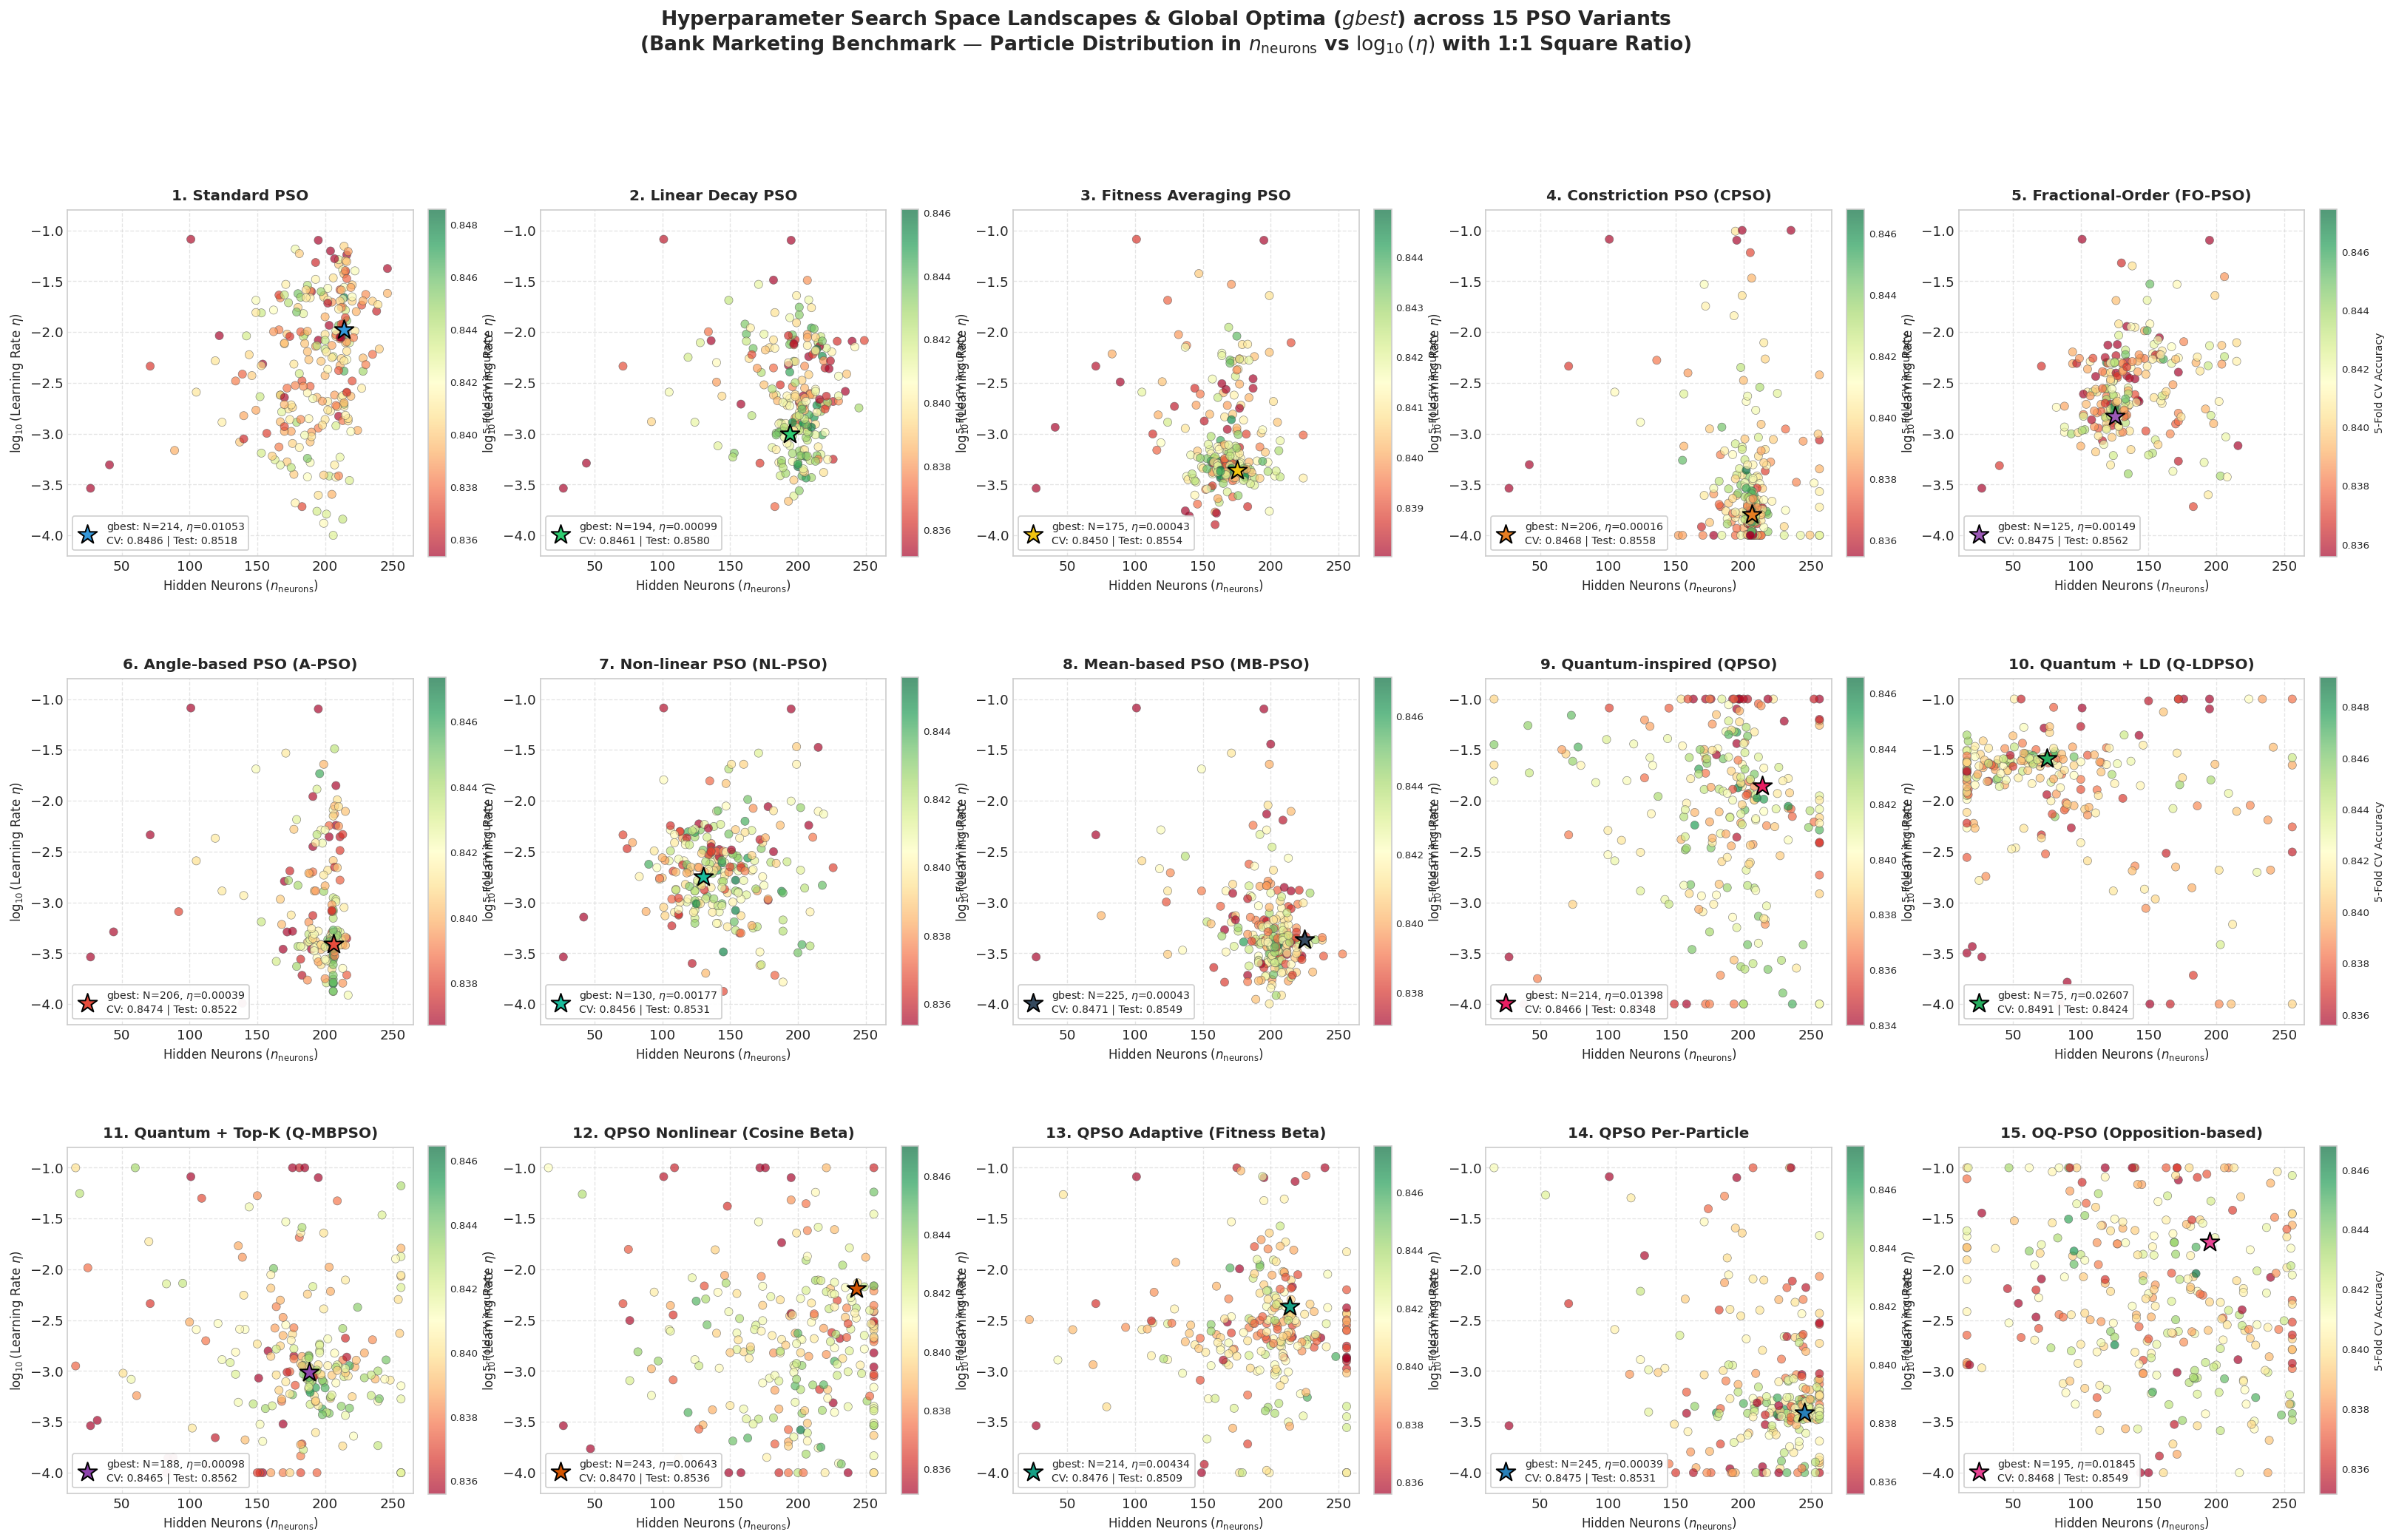

In [80]:
# BIỂU ĐỒ ĐỐI SÁNH LƯỚI 3x5 CẢ 15 BIẾN THỂ PSO (CHUẨN PUBLICATION TIẾNG ANH)
fig_15, axes = plt.subplots(3, 5, figsize=(33, 19))
plt.subplots_adjust(wspace=0.25, hspace=0.30)

def plot_sub(ax, hist, n_b, lr_b, title, cv_val, test_val, star_c='#e74c3c'):
    scores = hist['score']
    vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
    vmax = float(scores.max())
    sc = ax.scatter(hist['n_neurons'], np.log10(hist['lr']), c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax, alpha=0.68, s=45, edgecolors='#555555', lw=0.4)
    cb = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label('5-Fold CV Accuracy', fontsize=8.5)
    cb.ax.tick_params(labelsize=8)
    
    ax.scatter(n_b, np.log10(lr_b), c=star_c, s=260, marker='*', edgecolors='black', lw=1.2, zorder=6,
               label=f'gbest: N={n_b}, $\\eta$={lr_b:.5f}\nCV: {cv_val:.4f} | Test: {test_val:.4f}')
    ax.set_xlim(10, 265)
    ax.set_ylim(-4.2, -0.8)
    ax.set_aspect(abs((265 - 10) / (-0.8 - (-4.2))))
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel(r'Hidden Neurons ($n_{\\mathrm{neurons}}$)', fontsize=10)
    ax.set_ylabel(r'$\log_{10}(\\mathrm{Learning\\ Rate}\\ \\eta)$', fontsize=10)
    ax.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.95, fontsize=8.5)
    ax.grid(True, linestyle='--', alpha=0.5)

# Row 1: Algos 1 - 5
plot_sub(axes[0, 0], hist_standard_pso,     n_standard_pso,     lr_standard_pso,     '1. Standard PSO',                  cv_standard_pso,     test_standard_pso,     star_c='#3498db')
plot_sub(axes[0, 1], hist_linear_decay_pso,  n_linear_decay_pso,  lr_linear_decay_pso,  '2. Linear Decay PSO',              cv_linear_decay_pso,  test_linear_decay_pso,  star_c='#2ecc71')
plot_sub(axes[0, 2], hist_fitness_avg_pso,  n_fitness_avg_pso,  lr_fitness_avg_pso,  '3. Fitness Averaging PSO',         cv_fitness_avg_pso,  test_fitness_avg_pso,  star_c='#f1c40f')
plot_sub(axes[0, 3], hist_cpso,             n_cpso,             lr_cpso,             '4. Constriction PSO (CPSO)',       cv_cpso,             test_cpso,             star_c='#e67e22')
plot_sub(axes[0, 4], hist_fopso,            n_fopso,            lr_fopso,            '5. Fractional-Order (FO-PSO)',     cv_fopso,            test_fopso,            star_c='#9b59b6')

# Row 2: Algos 6 - 10
plot_sub(axes[1, 0], hist_apso,             n_apso,             lr_apso,             '6. Angle-based PSO (A-PSO)',       cv_apso,             test_apso,             star_c='#e74c3c')
plot_sub(axes[1, 1], hist_nl_pso,           n_nl_pso,           lr_nl_pso,           '7. Non-linear PSO (NL-PSO)',       cv_nl_pso,           test_nl_pso,           star_c='#1abc9c')
plot_sub(axes[1, 2], hist_mbpso,            n_mbpso,            lr_mbpso,            '8. Mean-based PSO (MB-PSO)',       cv_mbpso,            test_mbpso,            star_c='#34495e')
plot_sub(axes[1, 3], hist_qpso,             n_qpso,             lr_qpso,             '9. Quantum-inspired (QPSO)',       cv_qpso,             test_qpso,             star_c='#e91e63')
plot_sub(axes[1, 4], hist_q_ldpso,          n_q_ldpso,          lr_q_ldpso,          '10. Quantum + LD (Q-LDPSO)',       cv_q_ldpso,          test_q_ldpso,          star_c='#27ae60')

# Row 3: Algos 11 - 15
plot_sub(axes[2, 0], hist_q_mbpso,          n_q_mbpso,          lr_q_mbpso,          '11. Quantum + Top-K (Q-MBPSO)',    cv_q_mbpso,          test_q_mbpso,          star_c='#8e44ad')
plot_sub(axes[2, 1], hist_qpso_nonlinear,   n_qpso_nonlinear,   lr_qpso_nonlinear,   '12. QPSO Nonlinear (Cosine Beta)', cv_qpso_nonlinear,   test_qpso_nonlinear,   star_c='#d35400')
plot_sub(axes[2, 2], hist_qpso_adaptive,    n_qpso_adaptive,    lr_qpso_adaptive,    '13. QPSO Adaptive (Fitness Beta)',  cv_qpso_adaptive,    test_qpso_adaptive,    star_c='#16a085')
plot_sub(axes[2, 3], hist_qpso_per_particle, n_qpso_per_particle, lr_qpso_per_particle, '14. QPSO Per-Particle',       cv_qpso_per_particle, test_qpso_per_particle, star_c='#2980b9')
plot_sub(axes[2, 4], hist_oq_pso,           n_oq_pso,           lr_oq_pso,           '15. OQ-PSO (Opposition-based)',    cv_oq_pso,           test_oq_pso,           star_c='#e84393')

fig_15.suptitle('Hyperparameter Search Space Landscapes & Global Optima ($gbest$) across 15 PSO Variants\n(Bank Marketing Benchmark — Particle Distribution in $n_{\\mathrm{neurons}}$ vs $\\log_{10}(\\eta)$ with 1:1 Square Ratio)', 
               fontsize=16, fontweight='bold', y=0.995)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_15way_search_space_comparison.png', dpi=300, bbox_inches='tight')
plt.savefig('../../latex/figures/chart_15way_search_space_comparison_bank.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 📈 17. Biểu Đồ Đường Cong Hội Tụ Cả 15 Biến Thể PSO Trên Bank Marketing
So sánh tiến trình hội tụ qua 20 vòng lặp của **toàn bộ 15 thuật toán PSO** (8 biến thể cổ điển/cải tiến + QPSO + Q-LDPSO + Q-MBPSO + QPSO Nonlinear + QPSO Adaptive + QPSO Per-Particle + OQ-PSO).

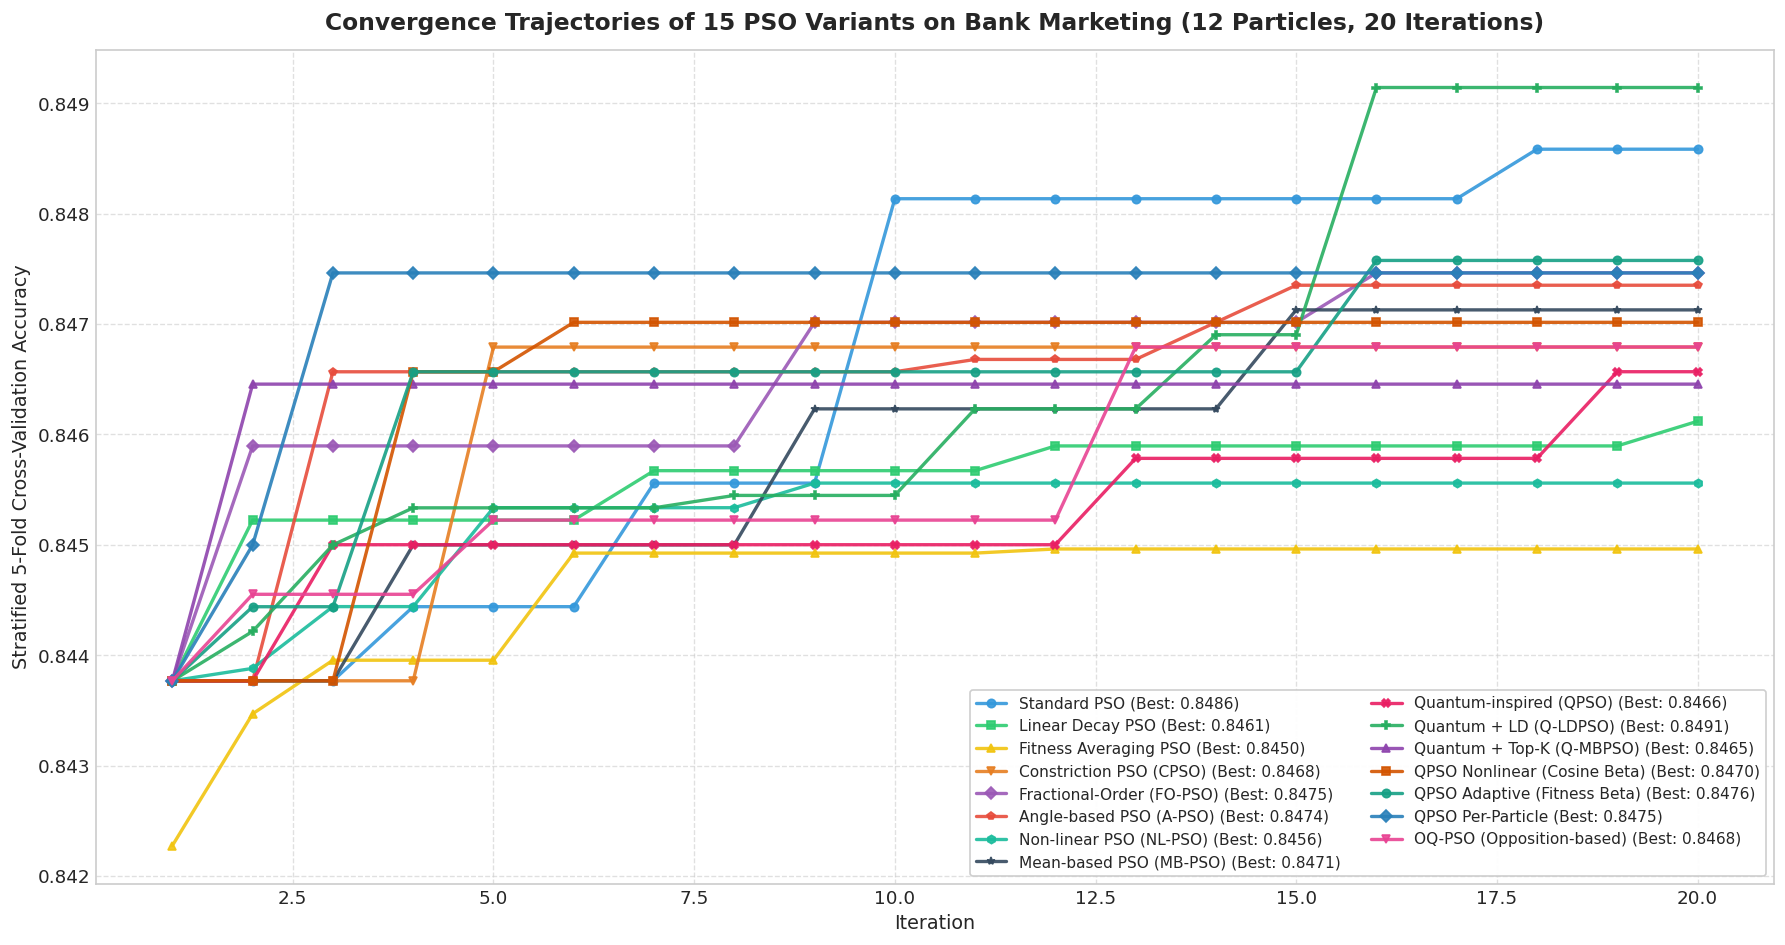

In [81]:
# CONVERGENCE TRAJECTORIES COMPARISON ACROSS 15 PSO VARIANTS
plt.figure(figsize=(15, 8))

algorithms = [
    ('Standard PSO', conv_standard_pso, '#3498db', 'o'),
    ('Linear Decay PSO', conv_linear_decay_pso, '#2ecc71', 's'),
    ('Fitness Avg PSO', conv_fitness_avg_pso, '#f1c40f', '^'),
    ('CPSO', conv_cpso, '#e67e22', 'v'),
    ('FO-PSO', conv_fopso, '#9b59b6', 'D'),
    ('A-PSO', conv_apso, '#e74c3c', 'p'),
    ('NL-PSO', conv_nl_pso, '#1abc9c', 'h'),
    ('MB-PSO', conv_mbpso, '#34495e', '*'),
    ('QPSO', conv_qpso, '#e91e63', 'X'),
    ('Q-LDPSO', conv_q_ldpso, '#27ae60', 'P'),
    ('Q-MBPSO', conv_q_mbpso, '#8e44ad', '^'),
    ('QPSO Nonlinear', conv_qpso_nonlinear, '#d35400', 's'),
    ('QPSO Adaptive', conv_qpso_adaptive, '#16a085', 'o'),
    ('QPSO Per-Particle', conv_qpso_per_particle, '#2980b9', 'D'),
    ('OQ-PSO', conv_oq_pso, '#e84393', 'v')
]

for name, conv, color, marker in algorithms:
    if len(conv) > 0:
        plt.plot(range(1, len(conv) + 1), conv, 
                 label=f'{name} (Best: {conv[-1]:.4f})', 
                 color=color, marker=marker, markersize=5, linewidth=2, alpha=0.9)

plt.title('Convergence Trajectories of 15 PSO Variants on Bank Marketing (12 Particles, 20 Iterations)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Iteration', fontsize=11.5)
plt.ylabel('Stratified 5-Fold Cross-Validation Accuracy', fontsize=11.5)
plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.2, ncol=2)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_convergence_comparison_15algos.png', dpi=300, bbox_inches='tight')
plt.savefig('../../latex/figures/chart_convergence_comparison_15algos_bank.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 📋 18. Bảng Tổng Hợp & Đồ Thị Đối Sánh Toàn Diện Trên Tập Test (15 Biến Thể)
Tổng kết hiệu năng kiểm định (CV Score) và kiểm thử độc lập (Test Accuracy) của **toàn bộ 15 thuật toán** trên bộ dữ liệu Bank Marketing.

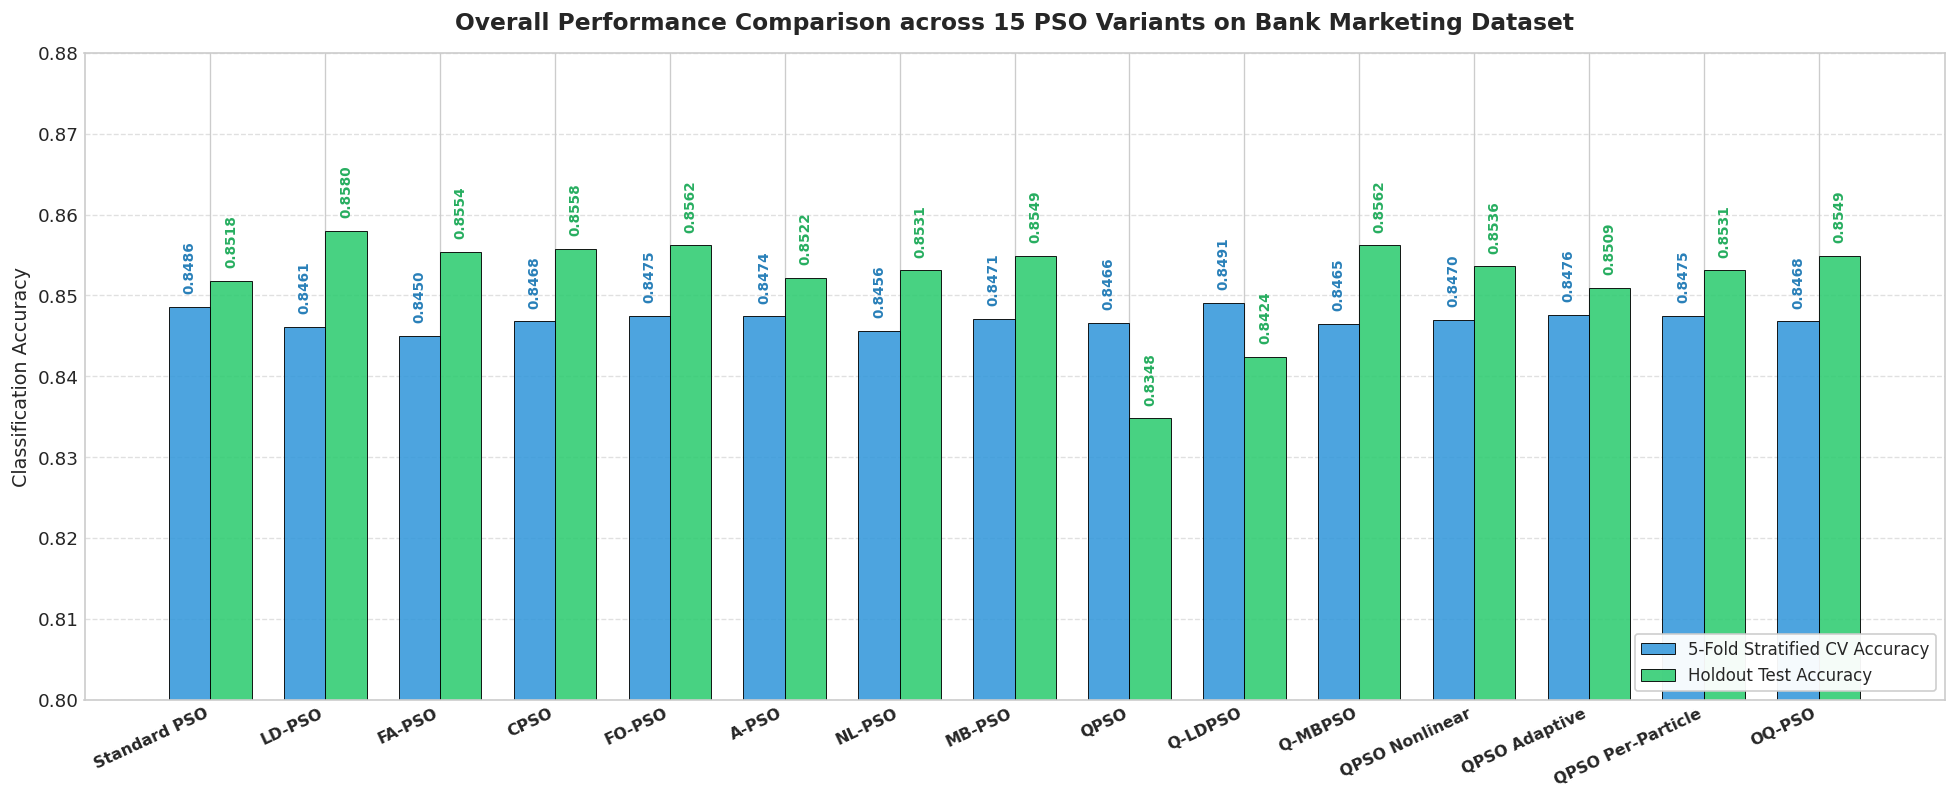

In [82]:
# EMPIRICAL VALIDATION VS TEST ACCURACY (GROUPED BAR CHART)
if os.path.exists(RESULT_CSV_PATH):
    df_results = pd.read_csv(RESULT_CSV_PATH)
    display(df_results)
    
    fig, ax_bar = plt.subplots(figsize=(20, 7))
    methods = [
        'Standard PSO', 'LD-PSO', 'FA-PSO', 'CPSO', 'FO-PSO',
        'A-PSO', 'NL-PSO', 'MB-PSO', 'QPSO', 'Q-LDPSO',
        'Q-MBPSO', 'QPSO Nonlinear', 'QPSO Adaptive', 'QPSO Per-Particle', 'OQ-PSO'
    ]
    x = np.arange(len(methods))
    w = 0.36
    
    ax_bar.bar(x - w/2, df_results['CV_Score'], w, label='5-Fold Stratified CV Accuracy', color='#3498db', alpha=0.88, edgecolor='black', lw=0.6)
    ax_bar.bar(x + w/2, df_results['Test_Accuracy'], w, label='Holdout Test Accuracy', color='#2ecc71', alpha=0.88, edgecolor='black', lw=0.6)
    
    for i in range(len(methods)):
        cv_val = df_results.loc[i, 'CV_Score']
        test_val = df_results.loc[i, 'Test_Accuracy']
        if pd.notnull(cv_val):
            ax_bar.text(x[i] - w/2, cv_val + 0.002, f'{cv_val:.4f}', ha='center', fontsize=8.2, fontweight='bold', color='#2980b9', rotation=90)
        if pd.notnull(test_val):
            ax_bar.text(x[i] + w/2, test_val + 0.002, f'{test_val:.4f}', ha='center', fontsize=8.2, fontweight='bold', color='#27ae60', rotation=90)
        
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(methods, fontsize=9.5, fontweight='bold', rotation=25, ha='right')
    ax_bar.set_ylim(0.80, 0.88)
    ax_bar.set_ylabel('Classification Accuracy', fontsize=11.5)
    ax_bar.set_title('Overall Performance Comparison across 15 PSO Variants on Bank Marketing Dataset', fontsize=14, fontweight='bold', pad=14)
    ax_bar.grid(True, axis='y', linestyle='--', alpha=0.6)
    ax_bar.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, fontsize=10)
    
    os.makedirs('../results/figures', exist_ok=True)
    plt.savefig('../results/figures/chart_overall_accuracy.png', dpi=300, bbox_inches='tight')
    plt.savefig('../../latex/figures/chart_overall_accuracy_bank.png', dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()

---
## 📊 19. Đối Sánh Hiệu Năng Test Accuracy Giữa 2 Bộ Dữ Liệu: Bank Marketing vs Forest Covertype (15 Biến Thể)
So sánh trực quan hiệu năng kiểm thử (Test Accuracy) của **toàn bộ 15 biến thể PSO** trên 2 bộ dữ liệu thực tế:
1. **Bộ Dữ Liệu 1 (Bank Marketing):** Bài toán phân loại nhị phân (Binary Classification) gồm 16 đặc trưng và 2 lớp.
2. **Bộ Dữ Liệu 2 (Forest Covertype):** Bài toán phân loại đa lớp (Multi-class Classification) gồm 54 đặc trưng và 7 loại rừng.

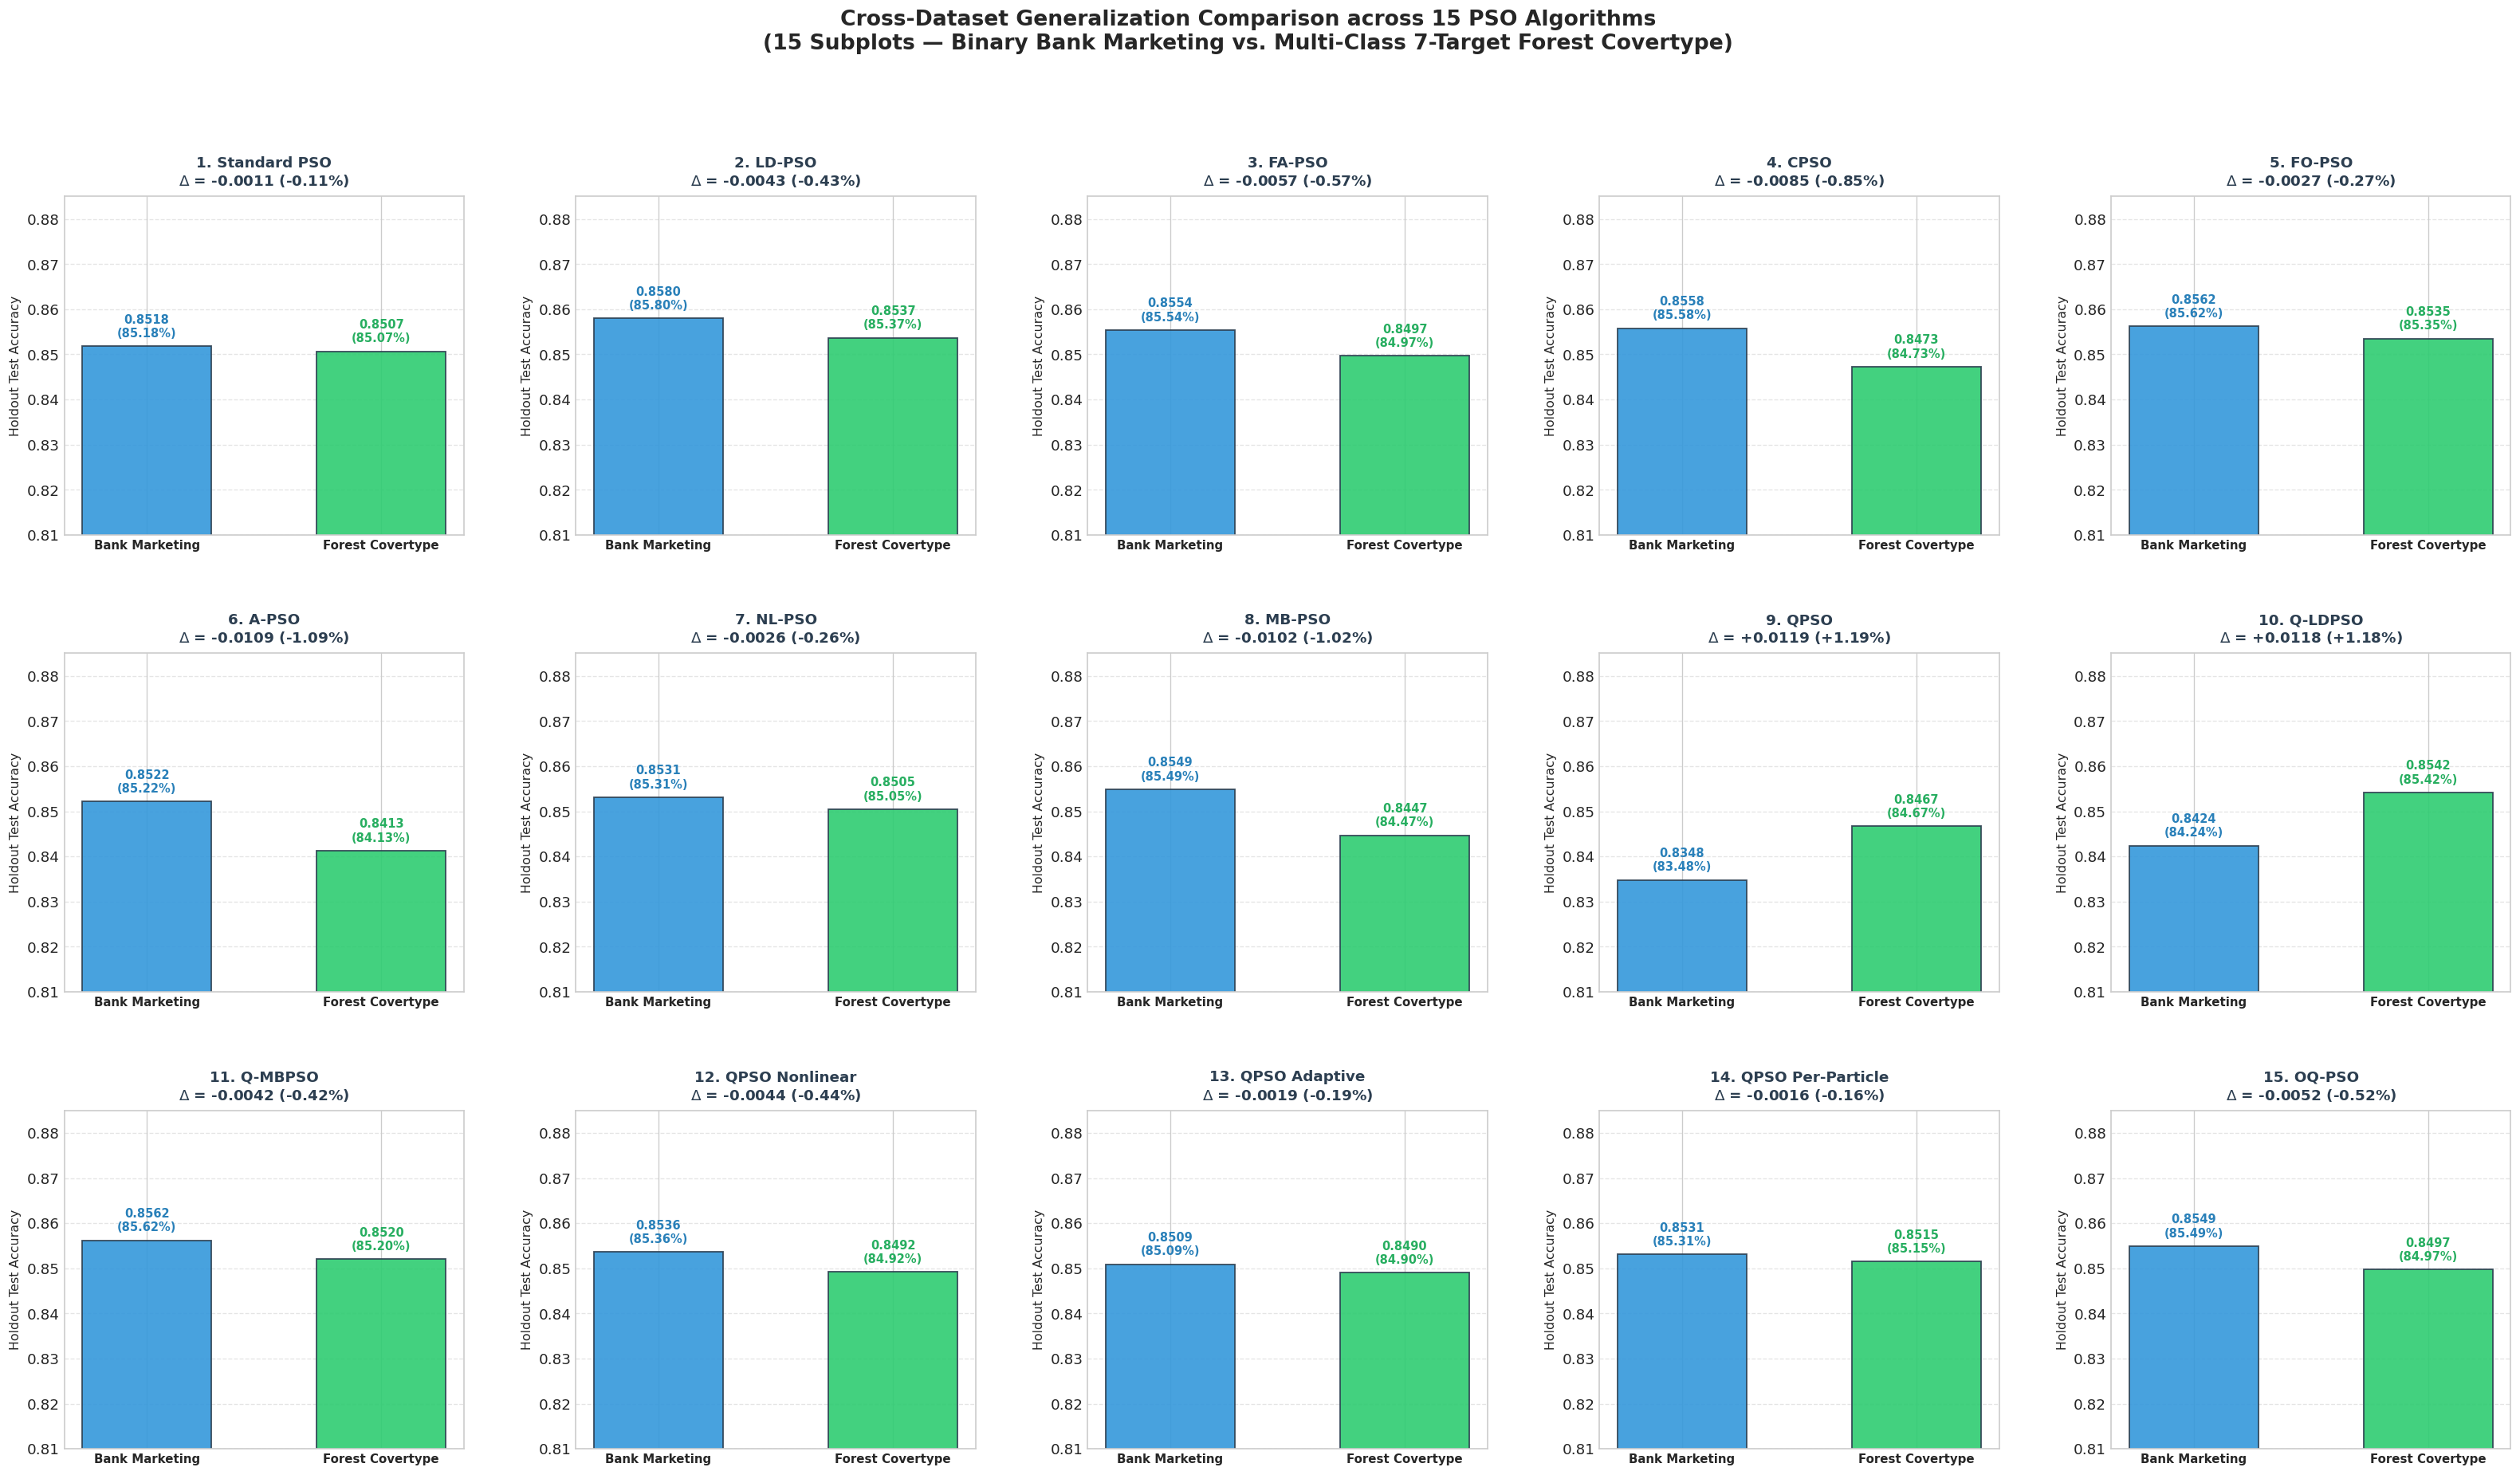

In [83]:
# CROSS-DATASET 15-SUBPLOT COMPARISON (3x5 GRID — BANK MARKETING VS FOREST COVERTYPE)
bank_csv = '../results/test_results/test_accuracy.csv'
cov_csv = '../../covertype/results/test_results/test_accuracy.csv'

df_bank = pd.read_csv(bank_csv)
df_cov  = pd.read_csv(cov_csv)

canonical_order = [
    'Standard PSO', 'LD-PSO', 'FA-PSO', 'CPSO', 'FO-PSO',
    'A-PSO', 'NL-PSO', 'MB-PSO', 'QPSO', 'Q-LDPSO',
    'Q-MBPSO', 'QPSO Nonlinear', 'QPSO Adaptive', 'QPSO Per-Particle', 'OQ-PSO'
]

bank_accs = df_bank['Test_Accuracy'].values
cov_accs = df_cov['Test_Accuracy'].values

fig_15h, axes = plt.subplots(3, 5, figsize=(33, 17))
plt.subplots_adjust(wspace=0.28, hspace=0.35)

color_b = '#3498db'
color_c = '#2ecc71'

for idx, algo in enumerate(canonical_order):
    ax = axes[idx // 5, idx % 5]
    b_acc = bank_accs[idx]
    c_acc = cov_accs[idx]
    diff_val = c_acc - b_acc
    
    x_bar = np.array([0, 1])
    bars = ax.bar(x_bar, [b_acc, c_acc], width=0.55, color=[color_b, color_c], edgecolor='#2c3e50', linewidth=1.1, alpha=0.9)
    
    ax.text(0, b_acc + 0.0015, f'{b_acc:.4f}\n({b_acc*100:.2f}%)', ha='center', va='bottom', fontsize=8.8, fontweight='bold', color='#2980b9')
    ax.text(1, c_acc + 0.0015, f'{c_acc:.4f}\n({c_acc*100:.2f}%)', ha='center', va='bottom', fontsize=8.8, fontweight='bold', color='#27ae60')
    
    ax.set_xticks(x_bar)
    ax.set_xticklabels(['Bank Marketing', 'Forest Covertype'], fontsize=9.0, fontweight='semibold')
    ax.set_ylim(0.81, 0.885)
    ax.set_ylabel('Holdout Test Accuracy', fontsize=9.5)
    
    diff_sign = '+' if diff_val > 0 else ''
    ax.set_title(f'{idx+1}. {algo}\n$\\Delta$ = {diff_sign}{diff_val:.4f} ({diff_sign}{diff_val*100:.2f}%)', fontsize=11, fontweight='bold', pad=8, color='#2c3e50')
    ax.grid(True, axis='y', linestyle='--', alpha=0.5)

fig_15h.suptitle('Cross-Dataset Generalization Comparison across 15 PSO Algorithms\n(15 Subplots — Binary Bank Marketing vs. Multi-Class 7-Target Forest Covertype)', 
               fontsize=16, fontweight='bold', y=0.995)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_cross_dataset_comparison_15algos.png', dpi=300, bbox_inches='tight')
plt.savefig('../../latex/figures/chart_cross_dataset_comparison_15algos.png', dpi=300, bbox_inches='tight')
plt.show()

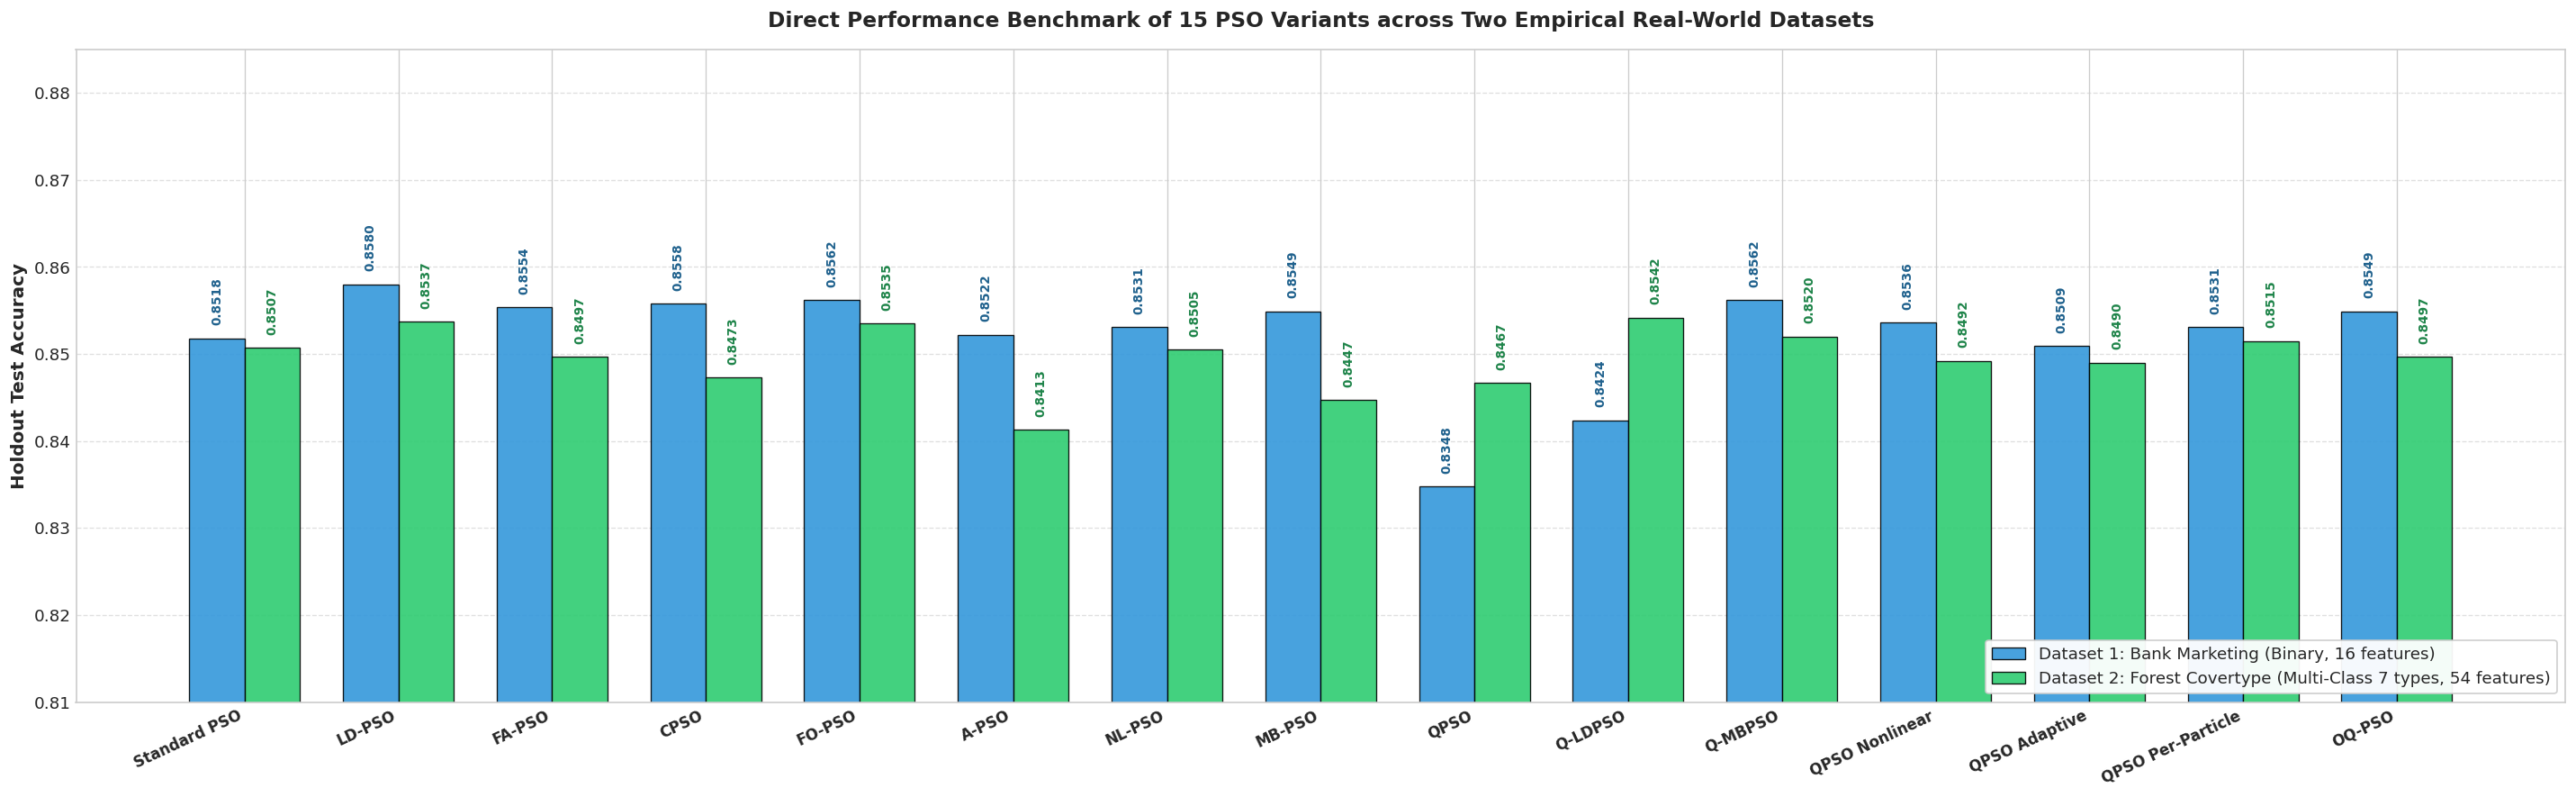

In [84]:
# DIRECT PERFORMANCE BENCHMARK (30-BAR GROUPED BAR CHART)
fig_30, ax_all = plt.subplots(figsize=(24, 7.5))
x_pos = np.arange(len(canonical_order))
width = 0.36

rects1 = ax_all.bar(x_pos - width/2, bank_accs, width, label='Dataset 1: Bank Marketing (Binary, 16 features)', color='#3498db', edgecolor='black', linewidth=0.8, alpha=0.9)
rects2 = ax_all.bar(x_pos + width/2, cov_accs, width, label='Dataset 2: Forest Covertype (Multi-Class 7 types, 54 features)', color='#2ecc71', edgecolor='black', linewidth=0.8, alpha=0.9)

for r in rects1:
    h = r.get_height()
    ax_all.text(r.get_x() + r.get_width()/2., h + 0.0015, f'{h:.4f}', ha='center', va='bottom', fontsize=8.2, fontweight='bold', color='#1f618d', rotation=90)
for r in rects2:
    h = r.get_height()
    ax_all.text(r.get_x() + r.get_width()/2., h + 0.0015, f'{h:.4f}', ha='center', va='bottom', fontsize=8.2, fontweight='bold', color='#1e8449', rotation=90)

ax_all.set_ylabel('Holdout Test Accuracy', fontsize=12, fontweight='bold')
ax_all.set_title('Direct Performance Benchmark of 15 PSO Variants across Two Empirical Real-World Datasets', fontsize=14, fontweight='bold', pad=15)
ax_all.set_xticks(x_pos)
ax_all.set_xticklabels(canonical_order, rotation=25, ha='right', fontsize=10, fontweight='bold')
ax_all.set_ylim(0.81, 0.885)
ax_all.legend(loc='lower right', fontsize=11, frameon=True, facecolor='white', framealpha=0.95)
ax_all.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.savefig('../results/figures/chart_dataset_comparison_30bars_overall.png', dpi=300, bbox_inches='tight')
plt.savefig('../../latex/figures/chart_dataset_comparison_30bars_overall.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 📑 20. Trình Xuất Bảng Kết Quả LaTeX Tự Động Chuẩn Publication (Results Back-fill)
Tự động sinh mã nguồn LaTeX chuẩn IEEE/Springer cho các bảng kết quả thực nghiệm và lưu thành các file `.tex` tại `../../latex/tables/`.

In [85]:
# TRÌNH TỰ ĐỘNG XUẤT BẢNG LATEX CHUẨN PUBLICATION
import os
os.makedirs('../../latex/tables', exist_ok=True)

df_bank = pd.read_csv('../results/test_results/test_accuracy.csv')
canonical_names = [
    'Standard PSO', 'LD-PSO', 'FA-PSO', 'CPSO', 'FO-PSO',
    'A-PSO', 'NL-PSO', 'MB-PSO', 'QPSO', 'Q-LDPSO',
    'Q-MBPSO', 'QPSO Nonlinear', 'QPSO Adaptive', 'QPSO Per-Particle', 'OQ-PSO'
]

paradigms = [
    'Baseline (Static $w=0.7$)',
    'Classical (Linear Decay $w$)',
    'Classical (Multi-Seed Avg $k=3$)',
    'Classical (Clerc Constriction $K$)',
    'Proposed (Fractional Memory $\\alpha=0.6$)',
    'Proposed (Directional Cosine Brake)',
    'Proposed (Non-linear Saturation)',
    'Proposed (Tri-Attractor Consensus)',
    'Quantum (Bare-bones $\\beta=0.75$)',
    'Quantum (Linear Decay $\\beta$)',
    'Quantum (Top-$K$ Mean-Best)',
    'Proposed Quantum (Cosine Decay $\\beta$)',
    'Proposed Quantum (Fitness-Adaptive $\\beta$)',
    'Proposed Quantum (Distance-Adaptive $\\beta$)',
    'Proposed Quantum (Opposition-Based)'
]

bank_best_cv = df_bank['CV_Score'].max()
bank_best_test = df_bank['Test_Accuracy'].max()

tex_bank = []
tex_bank.append(r"\begin{table}[htbp]")
tex_bank.append(r"\centering")
tex_bank.append(r"\fontsize{8.5pt}{11pt}\selectfont")
tex_bank.append(r"\caption{Empirical hyperparameter optimization and test generalization results on the Bank Marketing dataset across 15 Particle Swarm Optimization variants. The highest validation and test accuracies are highlighted in bold.}")
tex_bank.append(r"\label{tab:bank_marketing_15algos}")
tex_bank.append(r"\vspace{3pt}")
tex_bank.append(r"\begin{tabular}{llccccc}")
tex_bank.append(r"\hline\hline")
tex_bank.append(r"\textbf{Algorithm} & \textbf{Paradigm / Mechanism} & \textbf{CV Score} & \textbf{Test Acc.} & \textbf{$n_{\mathrm{neurons}}$} & \textbf{Learning Rate ($\eta$)} & \textbf{L2 Penalty ($\alpha$)} \\")
tex_bank.append(r"\hline")

for i in range(15):
    algo = canonical_names[i]
    para = paradigms[i]
    cv = df_bank.loc[i, 'CV_Score']
    test = df_bank.loc[i, 'Test_Accuracy']
    nn = int(df_bank.loc[i, 'n_neurons'])
    lr = float(df_bank.loc[i, 'lr'])
    al = float(df_bank.loc[i, 'alpha'])
    
    cv_str = f"\\textbf{{{cv:.4f}}}" if cv == bank_best_cv else f"{cv:.4f}"
    test_str = f"\\textbf{{{test:.4f}}}" if test == bank_best_test else f"{test:.4f}"
    
    if i in [4, 8, 11]:
        tex_bank.append(r"\hline")
    tex_bank.append(f"{algo} & {para} & {cv_str} & {test_str} & {nn} & {lr:.5f} & {al:.5f} \\\\")

tex_bank.append(r"\hline\hline")
tex_bank.append(r"\end{tabular}")
tex_bank.append(r"\end{table}")

tex_content = '\n'.join(tex_bank)
with open('../../latex/tables/table_results_15algos_bank.tex', 'w', encoding='utf-8') as f:
    f.write(tex_content)

print('✅ Đã xuất thành công bảng LaTeX: ../../latex/tables/table_results_15algos_bank.tex')
print('\n' + '='*70)
print(tex_content)
print('='*70)